---
title: "L3-08 · Entropy and uncertainty"
short_title: "Entropy and uncertainty"
subtitle: "Entropy is the average surprise of a random outcome, measured in bits: it is a property of the whole distribution, not of the outcome you happen to see, and it counts how many yes/no questions you need on average."
description: "Calculate the surprise of an outcome, the entropy of a distribution and the binary entropy $h(p)$, and distinguish the entropy of a distribution from the information carried by one outcome."
tags: [level-3, coursebook]
---

(lesson-l3-08)=

:::{div}
:class: qcai-meta
![Level 3 icon](../../_static/icons/qicon-level-3.svg) **Level 3 · High-school bridge** · about 80 minutes  
**Big idea.** Entropy is the average surprise of a random outcome, measured in bits: it is a property of the whole distribution, not of the outcome you happen to see, and it counts how many yes/no questions you need on average.  
**Before this lesson.** [L3-06](#lesson-l3-06), [L3-07](#lesson-l3-07)  
**Lab.** [Noise and quantum channels](../../labs/07-noise-channels.ipynb)
:::

## What you will be able to do

- Compute the surprise $-\log_2 p$ of an outcome and the entropy $H(X) = \sum_x p(x)\log_2 \frac{1}{p(x)}$ of a distribution, in bits.
- Compute and sketch the binary entropy $h(p)$, find its maximum, and explain why $h(p) = h(1-p)$.
- Prove that $0 \le H(X) \le \log_2 n$ for $n$ outcomes and say when each bound is reached.
- Explain entropy as the average number of yes/no questions an optimal strategy needs, and say why the match is exact only when every probability is a power of $1/2$.

## Why this matters

Which is more uncertain: a coin that lands heads 90% of the time, or a fair die? Variance cannot answer, because the faces of a coin and the faces of a die are not numbers on a common scale; you could relabel heads as 100 and the variance would jump while the uncertainty stays the same. We need a measure that looks only at the probabilities.

In 1948 Claude Shannon found that measure [@shannon1948]. Entropy tells you how many bits a message needs on average, how much a noisy channel can carry, and, in later levels, how much a measurement on a quantum system can reveal. It also gives a sharp warning: the information in the outcome you saw is not the same as the uncertainty you had before you looked. This lesson builds entropy from one idea, surprise, and checks every number by hand and in code.

:::{dropdown} Key terms

**Surprise (self-information)**
: $s(x) = -\log_2 p(x)$ bits: large for rare outcomes, zero for a certain one. It belongs to one outcome.

**Entropy**
: $H(X) = \sum_x p(x)\,(-\log_2 p(x))$, the expected surprise. It belongs to the whole distribution.

**Bit**
: The unit of entropy with base-2 logarithms: the uncertainty of one fair coin, or one well-chosen yes/no question.

**Binary entropy**
: $h(p) = -p\log_2 p - (1-p)\log_2(1-p)$, the entropy of a coin with $P(\text{heads}) = p$.

**Uniform distribution**
: All $n$ outcomes equally likely; it has the largest possible entropy, $\log_2 n$.

:::


In [1]:
import sys, pathlib, subprocess
here = pathlib.Path.cwd()
root = next((p for p in [here, *here.parents] if (p / "qcai").is_dir()), None)
if root is None:  # for example on Google Colab: fetch the course's small teaching package
    root = pathlib.Path("quantum-causal-ai")
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pozapas/quantum-causal-ai.git", str(root)], check=True)
    root = root.resolve()
sys.path.insert(0, str(root))
from qcai.viz import show as _show, show_mpl as _show_mpl
from qcai.lessonfigs import l3_08 as _lessonfigs

## Surprise: how unexpected is one outcome

An outcome that was almost certain tells you little when it happens; a rare outcome tells you a lot. We want a number $s(p)$ for the surprise of an outcome of probability $p$ that is zero when $p = 1$, grows as $p$ shrinks, and **adds** for independent events: two independent outcomes have probability $p\,q$, so we want $s(pq) = s(p) + s(q)$. Logarithms turn products into sums, which leads to the definition below.

:::{prf:definition} Surprise
:label: def-l3-08-surprise
The **surprise** (or self-information) of an outcome with probability $p > 0$ is $s = -\log_2 p$ bits. In this course logarithms in entropy are base 2 unless stated; base $e$ gives the same quantity in nats, and $1 \text{ bit} = \ln 2 \approx 0.693$ nats.
:::

$$
s(x) = -\log_2 p(x) = \log_2 \frac{1}{p(x)}
$$ (eq-l3-08-surprise)

:::{prf:example} Three surprises
:label: ex-l3-08-surprises
A fair coin landing heads: $-\log_2 \tfrac12 = 1$ bit. A fair die showing 6: $-\log_2 \tfrac16 = \log_2 6 \approx 2.585$ bits. An outcome of probability $\tfrac18$: $-\log_2 \tfrac18 = 3$ bits. Two independent fair coins both heads: probability $\tfrac14$, surprise $2 = 1 + 1$ bits, as additivity requires.
:::

:::{prf:remark} Why the logarithm and nothing else
If $s$ is continuous and $s(pq) = s(p) + s(q)$ for all $p, q$ in $(0, 1]$, then $s(p) = -c\log_2 p$ for a constant $c$. Writing $p = 2^{-u}$ and $f(u) = s(2^{-u})$ turns the condition into $f(u + v) = f(u) + f(v)$ (Cauchy's functional equation), whose continuous solutions are the linear functions $f(u) = cu$. Choosing $c = 1$ fixes the unit as the bit; another base gives another unit, the way meters and feet measure the same length. Shannon derived the entropy formula itself from a similar list of natural requirements [@shannon1948].
:::

## Entropy: surprise averaged over outcomes

:::{prf:definition} Shannon entropy
:label: def-l3-08-entropy
Let $X$ take values $x_1, \dots, x_n$ with probabilities $p_1, \dots, p_n$. Its **entropy** is the expected surprise, an expectation in the sense of [L3-07](#lesson-l3-07), with the convention $0 \log_2 0 = 0$ (outcomes that never happen contribute nothing).
:::

$$
H(X) = \mathbb{E}\big[-\log_2 p(X)\big] = -\sum_{i=1}^{n} p_i \log_2 p_i
$$ (eq-l3-08-entropy)

:::{figure} ../../_static/animations/l3_08_surprise_to_entropy.mp4
:alt: Four probability bars of heights one half, one quarter, one eighth, one eighth turn into surprise bars of heights 1, 2, 3, 3 bits, and a weighted sum collapses to 1.75 bits.
:width: 100%

Probabilities become surprises $-\log_2 p$, and the probability-weighted average of the surprises is the entropy, $1.75$ bits. Seeing D carries 3 bits, but the entropy is still $1.75$.
:::

:::{dropdown} What the animation shows
Blue bars show the distribution of four outcomes A, B, C, D with probabilities $\tfrac12, \tfrac14, \tfrac18, \tfrac18$. Each bar is copied and reshaped into an orange surprise bar of height $-\log_2 p$: 1, 2, 3 and 3 bits, so the rare outcomes get the tall bars. A formula appears, $H = \tfrac12\cdot 1 + \tfrac14\cdot 2 + \tfrac18\cdot 3 + \tfrac18\cdot 3$, which becomes $0.5 + 0.5 + 0.375 + 0.375$ and then $H = 1.75$ bits. Finally the bar for D is boxed in red: observing D carries 3 bits of surprise, while $H = 1.75$ bits is the average you expect before you look.
:::

For the distribution $(\tfrac12, \tfrac14, \tfrac18, \tfrac18)$ in the animation, [](#eq-l3-08-entropy) gives $H = \tfrac12\cdot 1 + \tfrac14\cdot 2 + \tfrac18\cdot 3 + \tfrac18\cdot 3 = 1.75$ bits. Every single outcome has a surprise of 1, 2 or 3 bits; none has surprise 1.75. Entropy, like a mean, need not be a value any single outcome takes.

:::{important} Entropy is not the information in one outcome
The surprise $-\log_2 p(x)$ belongs to the outcome $x$ you observed. The entropy $H(X)$ belongs to the distribution and is fixed before anything is observed. A coin with $P(\text{heads}) = 0.1$ has entropy $0.469$ bits; if it lands heads, that outcome carries $3.322$ bits, more than the entropy; if it lands tails, only $0.152$ bits.
:::

:::{note} Entropy ignores the values
Entropy uses only the probabilities. If $X$ is a fair coin coded 0 or 1, and $Y = 100X$, then $H(X) = H(Y) = 1$ bit, while $\operatorname{Var}(X) = 0.25$ and $\operatorname{Var}(Y) = 2500$. Variance measures spread of numbers; entropy measures uncertainty about which outcome occurs.
:::

## The range of entropy: certainty to uniform


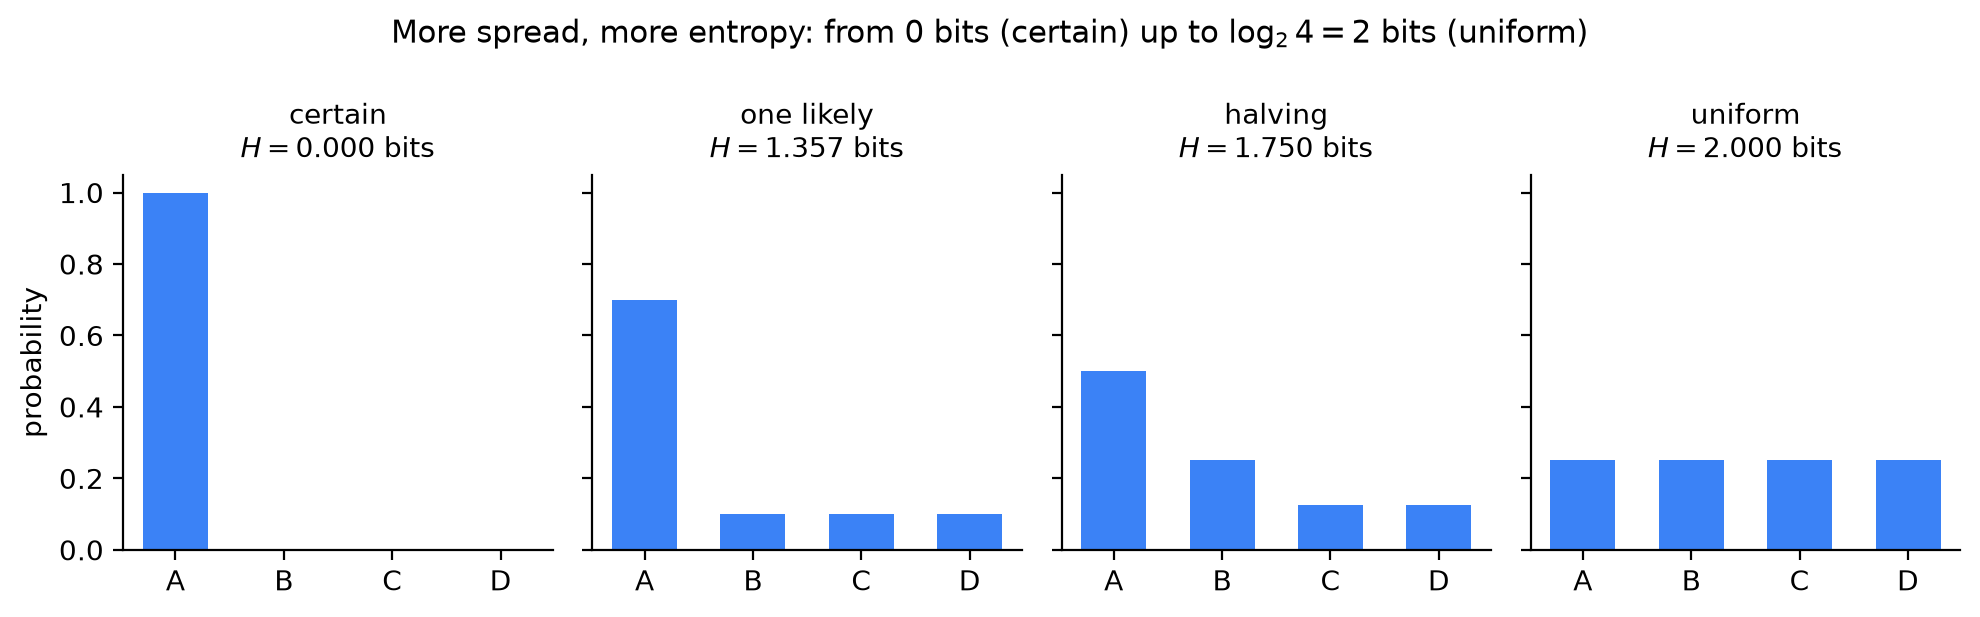

In [2]:
_show_mpl(_lessonfigs.four_distributions())

*Four distributions on four outcomes. The certain one has $H = 0$, the one with a likely outcome has $H \approx 1.357$ bits, the halving one $1.75$ bits, and the uniform one the maximum, $\log_2 4 = 2$ bits.*

:::{prf:lemma} Jensen's inequality for the logarithm
:label: lem-l3-08-jensen
For a random variable $Y > 0$ taking finitely many values, $\mathbb{E}[\log_2 Y] \le \log_2 \mathbb{E}[Y]$, with equality only if $Y$ is constant on the outcomes of positive probability.
:::

:::{prf:proof}
The function $f(y) = \log_2 y$ is concave: its second derivative $-1/(y^2 \ln 2)$ is negative, so its graph lies below each tangent line. Let $m = \mathbb{E}[Y]$ and take the tangent at $m$: $\log_2 y \le \log_2 m + \frac{y - m}{m \ln 2}$ for all $y > 0$, with equality only at $y = m$. Put $y = Y$ and take expectations; the last term has mean $\frac{\mathbb{E}[Y] - m}{m\ln 2} = 0$. So $\mathbb{E}[\log_2 Y] \le \log_2 m$, and equality needs $Y = m$ whenever it has positive probability.
:::

:::{prf:theorem} Bounds on entropy
:label: thm-l3-08-bounds
If $X$ has $n$ possible outcomes, then $0 \le H(X) \le \log_2 n$. The lower bound holds with equality exactly when one outcome is certain; the upper bound holds with equality exactly when all $n$ outcomes are equally likely [@coverthomas].
:::

:::{prf:proof}
Lower bound: each term $-p_i\log_2 p_i$ is $\ge 0$ because $0 \le p_i \le 1$ makes $\log_2 p_i \le 0$. A term is zero only when $p_i = 0$ or $p_i = 1$, so $H = 0$ exactly when one $p_i$ equals 1. Upper bound: restrict to outcomes with $p_i > 0$ (there are at most $n$) and let $Y = 1/p(X)$. Then $H(X) = \mathbb{E}[\log_2 Y] \le \log_2 \mathbb{E}[Y]$ by [](#lem-l3-08-jensen), and $\mathbb{E}[Y] = \sum_{p_i > 0} p_i \cdot \frac{1}{p_i} \le n$. Equality needs $1/p_i$ constant over outcomes with $p_i > 0$ and all $n$ outcomes to have $p_i > 0$, which means $p_i = 1/n$ for every $i$. Then $H = \sum \frac1n \log_2 n = \log_2 n$.
:::

:::{prf:proposition} Independent parts add
:label: prop-l3-08-additive
If $X$ and $Y$ are independent, the entropy of the pair is $H(X, Y) = H(X) + H(Y)$.
:::

:::{prf:proof}
Independence gives $p(x, y) = p(x)\,q(y)$, so $-\log_2 p(x, y) = -\log_2 p(x) - \log_2 q(y)$: surprises add outcome by outcome. Take the expectation of both sides; expectation is linear ([L3-07](#lesson-l3-07)), so $H(X, Y) = \mathbb{E}[-\log_2 p(X)] + \mathbb{E}[-\log_2 q(Y)] = H(X) + H(Y)$. For example, three fair coins have $H = 3$ bits, the same as one draw from 8 equally likely outcomes.
:::

## Binary entropy

A coin with $P(\text{heads}) = p$ is the simplest uncertain system: a yes/no event, a bit flipped by noise, or a qubit measured in a fixed basis. Its entropy has its own name.

$$
h(p) = -p\log_2 p - (1-p)\log_2(1-p)
$$ (eq-l3-08-binary)

:::{figure} ../../_static/animations/l3_08_binary_entropy.mp4
:alt: Two bars for heads and tails change height as p sweeps from 0 to 1, while a red dot traces the hump-shaped curve h(p).
:width: 100%

As $p$ sweeps from 0 to 1, the coin's bars change and the dot traces $h(p)$: 0 at the ends, $0.469$ at $p = 0.1$, and the maximum of 1 bit at $p = 0.5$.
:::

:::{dropdown} What the animation shows
On the left, a blue bar shows $P(\text{heads}) = p$ and a cyan bar shows $P(\text{tails}) = 1 - p$, with live readouts of $p$ and $h$. On the right, axes from 0 to 1 in both directions. As $p$ grows from 0 a red dot traces the curve $h(p)$. At $p = 0.1$ the curve is marked: $h(0.1) = 0.469$. At $p = 0.5$ it reaches its top, 1 bit, labeled as the fair coin. It then falls back to 0 at $p = 1$, labeled certain. The formula $h(p) = -p\log_2 p - (1-p)\log_2(1-p)$ appears below, with the note that the curve is symmetric, $h(p) = h(1-p)$.
:::


In [3]:
_show(_lessonfigs.entropy_explorer())

**Explore.** Move the slider to change $P(\text{heads})$. The left panel shows each face's probability and its surprise in bits; the right panel shows the entropy, which is the probability-weighted average of the two surprises.

:::{dropdown} What the figure shows
Left panel: grouped bars for heads and tails, blue for probability and orange for surprise in bits. At $p = 0.1$ the heads surprise is 3.322 bits and the tails surprise is 0.152 bits. Right panel: the curve $h(p)$ for $p$ from 0 to 1 with a marker at the chosen $p$; at $p = 0.1$ the marker is at 0.469 bits, at $p = 0.5$ at 1 bit.
:::

:::{prf:proposition} Shape of the binary entropy
:label: prop-l3-08-shape
On $0 < p < 1$, $h'(p) = \log_2 \frac{1-p}{p}$. So $h$ increases for $p < \tfrac12$, decreases for $p > \tfrac12$, and has its maximum $h(\tfrac12) = 1$ bit. Also $h(p) = h(1-p)$.
:::

:::{prf:proof}
Write $\log_2 u = \ln u / \ln 2$ and differentiate with the product rule ([L3-06](#lesson-l3-06)) and the standard fact $\frac{d}{dp}\ln p = \frac{1}{p}$: $\frac{d}{dp}[-p\ln p] = -\ln p - 1$ and $\frac{d}{dp}[-(1-p)\ln(1-p)] = \ln(1-p) + 1$. The sum is $\ln\frac{1-p}{p}$; divide by $\ln 2$. This is positive when $1 - p > p$, zero at $p = \tfrac12$ and negative after. Swapping $p$ and $1-p$ swaps the two terms of [](#eq-l3-08-binary), so $h(p) = h(1-p)$.
:::

The curve is steep near the ends and flat near the top. A coin with $p = 0.11$ already has $h \approx 0.500$ bits, half the uncertainty of a fair coin, and $h(0.25) \approx 0.811$.

## Bits as yes/no questions

A friend picks one of 8 equally likely objects. Asking "Is it in the first half?" splits the possibilities evenly, so 3 questions always suffice, and $\log_2 8 = 3$. When outcomes are not equally likely, a good questioner asks about the likely ones first.

:::{figure} ../../_static/animations/l3_08_question_tree.mp4
:alt: A balanced tree of three yes/no questions leading to 8 leaves, then a lopsided tree for outcomes A, B, C, D with 1, 2, 3, 3 questions.
:width: 100%

For 8 equally likely outcomes, $\log_2 8 = 3$ questions. For $(\tfrac12, \tfrac14, \tfrac18, \tfrac18)$, asking about A first needs $1.75$ questions on average, exactly the entropy.
:::

:::{dropdown} What the animation shows
First a balanced binary tree with 8 leaves numbered 1 to 8. A path highlights the questions "Is it in 1 to 4?", "Then 5 or 6?", "Then 6?", reaching leaf 6 in 3 steps, and the caption reads: 8 equally likely outcomes, $\log_2 8 = 3$ questions. Then a lopsided tree: the first question is "A?"; yes leads to A (probability one half, 1 question), no leads to "B?" (B has probability one quarter, 2 questions), then "C?" separates C and D (one eighth each, 3 questions). The average number of questions is $\tfrac12\cdot 1 + \tfrac14\cdot 2 + \tfrac18\cdot 3 + \tfrac18\cdot 3 = 1.75 = H$, exact because every probability is a power of $\tfrac12$. A small table then lists uniform entropies $H = \log_2 n$: 1, 2, 3, 4 bits for $n$ = 2, 4, 8, 16.
:::

```{mermaid}
graph TD
  Q1{"Is it A?"} -->|"yes, prob 1/2"| A["A: 1 question"]
  Q1 -->|"no"| Q2{"Is it B?"}
  Q2 -->|"yes, prob 1/4"| B["B: 2 questions"]
  Q2 -->|"no"| Q3{"Is it C?"}
  Q3 -->|"yes, prob 1/8"| C["C: 3 questions"]
  Q3 -->|"no, prob 1/8"| D["D: 3 questions"]
```

*An optimal question strategy for $(\tfrac12, \tfrac14, \tfrac18, \tfrac18)$. Writing yes as 0 and no as 1 turns it into the binary code A = 0, B = 10, C = 110, D = 111.*

:::{prf:theorem} Entropy bounds the number of questions
:label: thm-l3-08-coding
Let $L^*$ be the smallest possible average number of yes/no questions (equivalently, the shortest average length of a binary code in which no codeword begins another) needed to identify the outcome of $X$. Then $H(X) \le L^* < H(X) + 1$. The lower bound is reached exactly when every probability is a power of $\tfrac12$. Coding long blocks of independent outcomes together brings the average per outcome as close to $H(X)$ as we like [@coverthomas; @shannon1948].
:::

:::{prf:remark} About the proof
The lower bound follows from Kraft's inequality $\sum_i 2^{-\ell_i} \le 1$ for codeword lengths $\ell_i$ together with [](#lem-l3-08-jensen); the upper bound from choosing $\ell_i = \lceil -\log_2 p_i \rceil$. Cover and Thomas, chapter 5, give both proofs [@coverthomas]. For the coin with $p = 0.1$ a single flip still costs 1 question, but long runs of flips can be described with about $0.469$ bits per flip.
:::

## Compute it: entropy, sampling, and a noisy bit

An entropy function, the numbers of this lesson, and a check that the average surprise of many samples settles near $H$ (the law of large numbers from [L3-07](#lesson-l3-07)).


In [4]:
import math
import numpy as np

def entropy(ps):
    """Shannon entropy in bits, with 0 log 0 = 0."""
    return sum(-p * math.log2(p) for p in ps if p > 0)

def h(p):
    return entropy([p, 1 - p])

print('H(1/2,1/4,1/8,1/8) =', entropy([1/2, 1/4, 1/8, 1/8]))
print('fair die  =', round(entropy([1/6] * 6), 3), ' log2 6 =', round(math.log2(6), 3))
print('h(0.1) =', round(h(0.1), 3), ' h(0.5) =', h(0.5), ' h(0.11) =', round(h(0.11), 3))
print('surprise of heads at p = 0.1:', round(-math.log2(0.1), 3), ' of tails:', round(-math.log2(0.9), 3))

# average surprise of samples approaches H
rng = np.random.default_rng(8)
p = np.array([1/2, 1/4, 1/8, 1/8])
for n in (10, 100, 10_000):
    x = rng.choice(4, size=n, p=p)
    print(f'n = {n:>6}: mean surprise = {np.mean(-np.log2(p[x])):.3f} bits')

H(1/2,1/4,1/8,1/8) = 1.75
fair die  = 2.585  log2 6 = 2.585
h(0.1) = 0.469  h(0.5) = 1.0  h(0.11) = 0.5
surprise of heads at p = 0.1: 3.322  of tails: 0.152
n =     10: mean surprise = 1.600 bits
n =    100: mean surprise = 1.540 bits
n =  10000: mean surprise = 1.757 bits


Independent parts add, and a noisy bit. A **binary symmetric channel** flips a bit with probability $f$. With a fair input bit the output is still fair, so its entropy is 1 bit, but $h(f)$ of it is noise; the information the output keeps about the input is $1 - h(f)$ bits [@coverthomas].


In [5]:
from itertools import product

# H(X, Y) = H(X) + H(Y) for independent X, Y
px, py = [0.7, 0.3], [1/2, 1/4, 1/4]
joint = [a * b for a, b in product(px, py)]
print('H(X) + H(Y) =', round(entropy(px) + entropy(py), 6), ' H(X, Y) =', round(entropy(joint), 6))

# binary symmetric channel with flip probability f and a fair input bit
for f in (0.0, 0.11, 0.25, 0.5):
    p_out1 = 0.5 * (1 - f) + 0.5 * f
    print(f'f = {f:.2f}: H(output) = {entropy([p_out1, 1 - p_out1]):.3f}, noise h(f) = {h(f):.3f}, kept = {1 - h(f):.3f} bits')

H(X) + H(Y) = 2.381291  H(X, Y) = 2.381291
f = 0.00: H(output) = 1.000, noise h(f) = 0.000, kept = 1.000 bits
f = 0.11: H(output) = 1.000, noise h(f) = 0.500, kept = 0.500 bits
f = 0.25: H(output) = 1.000, noise h(f) = 0.811, kept = 0.189 bits
f = 0.50: H(output) = 1.000, noise h(f) = 1.000, kept = 0.000 bits


:::{prf:remark} Looking ahead to quantum measurement
Measuring the qubit state $\cos\theta\,|0\rangle + \sin\theta\,|1\rangle$ in the basis $|0\rangle, |1\rangle$ gives outcome 0 with probability $\cos^2\theta$, so the outcome entropy is $h(\cos^2\theta)$. Measuring the same state in another basis gives different probabilities and a different entropy. Level 5 ([L5-09](#lesson-l5-09)) introduces the von Neumann entropy, which belongs to the state itself.
:::

## Worked example

:::{admonition} A biased coin: surprise versus entropy
:class: tip

A coin lands heads with probability $0.1$. Find the surprise of each face, the entropy of one flip, and compare with a fair coin. About how many bits does a long record of $1000$ flips need?

1. Surprise of heads: $-\log_2 0.1 = \log_2 10 \approx 3.322$ bits. Surprise of tails: $-\log_2 0.9 \approx 0.152$ bits.
2. Entropy is the probability-weighted average: $h(0.1) = 0.1 \times 3.322 + 0.9 \times 0.152 \approx 0.332 + 0.137 = 0.469$ bits.
3. A fair coin has $h(0.5) = 1$ bit, so this coin carries less than half the uncertainty, even though one of its outcomes is more surprising (3.322 bits) than either face of a fair coin.
4. For long runs of independent flips, [](#thm-l3-08-coding) applied to blocks says about $1000 \times 0.469 \approx 469$ bits suffice on average, instead of $1000$ bits for one bit per flip.

**Result.** $h(0.1) \approx 0.469$ bits. Heads carries $3.322$ bits and tails $0.152$ bits; the entropy is their average, not the surprise of either outcome.
:::

## Exercises

**1. (Core)** Find the entropy of one roll of a fair six-sided die, and the surprise of rolling a 6. Why are they equal here?

:::{dropdown} Solution
$H = -\sum_{i=1}^{6} \tfrac16\log_2\tfrac16 = \log_2 6 \approx 2.585$ bits. The surprise of a 6 is $-\log_2\tfrac16 = \log_2 6$, the same number. They agree because for a uniform distribution every outcome has the same surprise, so the average equals each value. For a non-uniform distribution they differ.
:::

**2. (Core)** Compute $H$ for the distribution $(\tfrac12, \tfrac14, \tfrac14)$ and design a yes/no question strategy whose average number of questions equals $H$.

:::{dropdown} Solution
$H = \tfrac12\cdot 1 + \tfrac14\cdot 2 + \tfrac14\cdot 2 = 1.5$ bits. Ask first "Is it the first outcome?" (probability $\tfrac12$, 1 question). If not, ask "Is it the second?" to separate the two remaining outcomes (2 questions each). Average: $\tfrac12\cdot 1 + \tfrac12\cdot 2 = 1.5$ questions.
:::

**3. (Stretch)** Let $X$ be a fair coin coded 0 or 1, and $Y = 100X$. Compute $H(X)$, $H(Y)$, $\operatorname{Var}(X)$ and $\operatorname{Var}(Y)$. What does the comparison show?

:::{dropdown} Solution
Both take two values with probability $\tfrac12$ each, so $H(X) = H(Y) = 1$ bit. $\operatorname{Var}(X) = \mathbb{E}[X^2] - (\mathbb{E}X)^2 = \tfrac12 - \tfrac14 = 0.25$ and $\operatorname{Var}(Y) = 100^2 \cdot 0.25 = 2500$. Entropy depends only on the probabilities, while variance depends on the values; relabeling outcomes changes variance but not entropy.
:::

**4. (Stretch)** Use $h'(p) = \log_2\frac{1-p}{p}$ to find $h'(0.1)$ and $h'(0.5)$. Estimate $h(0.12)$ from $h(0.1) \approx 0.469$ with a tangent line, then check it exactly.

:::{dropdown} Solution
$h'(0.1) = \log_2 9 \approx 3.170$ and $h'(0.5) = \log_2 1 = 0$. Tangent estimate: $h(0.12) \approx 0.469 + 0.02 \times 3.170 \approx 0.532$. Exactly, $h(0.12) = -0.12\log_2 0.12 - 0.88\log_2 0.88 \approx 0.367 + 0.162 = 0.529$; the tangent slightly overestimates because $h$ is concave.
:::

**5. (Challenge)** Prove the grouping rule: for $p_1 < 1$, $H(p_1, p_2, \dots, p_n) = h(p_1) + (1 - p_1)\,H\!\left(\frac{p_2}{1-p_1}, \dots, \frac{p_n}{1-p_1}\right)$. Check it on $(\tfrac12, \tfrac14, \tfrac18, \tfrac18)$ and interpret it as a question strategy.

:::{dropdown} Solution
Let $q = 1 - p_1$ and $r_i = p_i / q$ for $i \ge 2$, so $\sum_{i \ge 2} r_i = 1$. Then $q\,H(r) = -\sum_{i\ge2} p_i \log_2 \frac{p_i}{q} = -\sum_{i \ge 2} p_i\log_2 p_i + q\log_2 q$. Add $h(p_1) = -p_1\log_2 p_1 - q\log_2 q$: the $q\log_2 q$ terms cancel, leaving $-\sum_{i=1}^n p_i\log_2 p_i = H(p)$. Check: $h(\tfrac12) = 1$ and $\tfrac12 H(\tfrac12, \tfrac14, \tfrac14) = \tfrac12 \times 1.5 = 0.75$, total $1.75$. Interpretation: first ask "Is it outcome 1?" (uncertainty $h(p_1)$); with probability $1 - p_1$ the answer is no and the remaining uncertainty is the entropy of the renormalized rest.
:::

**6. (Challenge)** A fair bit passes through a binary symmetric channel that flips it with probability $f$. Using $I = H(\text{output}) - H(\text{output} \mid \text{input})$, where $H(\text{output} \mid \text{input}) = \sum_x P(\text{input} = x)\,H(\text{output} \mid \text{input} = x)$, show that $I = 1 - h(f)$. For which $f$ is $I = 0$, and what is $I$ at $f = 0.11$?

:::{dropdown} Solution
$P(\text{output} = 1) = \tfrac12(1 - f) + \tfrac12 f = \tfrac12$, so $H(\text{output}) = 1$ bit. Given either input, the output is flipped with probability $f$, so $H(\text{output} \mid \text{input} = x) = h(f)$ for both $x$, and the weighted average is $h(f)$. Hence $I = 1 - h(f)$. It is 0 only when $h(f) = 1$, that is $f = \tfrac12$: the output is then independent of the input. At $f = 0.11$, $I \approx 1 - 0.500 = 0.500$ bits, about half a bit per use.
:::

## Check your understanding

**1. What is the entropy of the distribution $(\tfrac12, \tfrac14, \tfrac18, \tfrac18)$?**

- **A.** 0.25 bits
- **B.** 1.75 bits
- **C.** 2 bits
- **D.** 3 bits

:::{dropdown} Show the answer
**B. 1.75 bits**

$H = \tfrac12\cdot 1 + \tfrac14\cdot 2 + \tfrac18\cdot 3 + \tfrac18\cdot 3 = 1.75$ bits. Two bits would be the uniform distribution on four outcomes; 3 bits is the surprise of one rare outcome.
:::

**2. A coin lands heads with probability 0.1. You flip it and see heads. Which quantity equals about 3.322 bits?**

- **A.** The expected number of heads in one flip
- **B.** The surprise of the outcome you saw
- **C.** The entropy of the coin
- **D.** The maximum possible entropy of a coin

:::{dropdown} Show the answer
**B. The surprise of the outcome you saw**

The surprise of heads is $-\log_2 0.1 \approx 3.322$ bits. The entropy of the coin is the average surprise, $h(0.1) \approx 0.469$ bits, and the maximum for any coin is 1 bit.
:::

**3. Among all distributions on 4 outcomes, which has the largest entropy?**

- **A.** The distribution $(0.7, 0.1, 0.1, 0.1)$
- **B.** The distribution with one certain outcome
- **C.** Any distribution: entropy is always 2 bits on 4 outcomes
- **D.** The uniform distribution, with 2 bits

:::{dropdown} Show the answer
**D. The uniform distribution, with 2 bits**

By the bounds theorem, $H \le \log_2 4 = 2$ bits, with equality only for the uniform distribution. A certain outcome gives 0 bits and $(0.7, 0.1, 0.1, 0.1)$ gives about 1.357 bits.
:::

**4. A fair coin is coded $X = 1$ for heads and $X = 0$ for tails. What is $\operatorname{Var}(X)$?** *(Review of [L3-07](#lesson-l3-07))*

- **A.** 1
- **B.** 0.25
- **C.** 0
- **D.** 0.5

:::{dropdown} Show the answer
**B. 0.25**

$\mathbb{E}[X] = 0.5$ and $\mathbb{E}[X^2] = 0.5$, so $\operatorname{Var}(X) = 0.5 - 0.25 = 0.25$. Its entropy is 1 bit; the two measures answer different questions.
:::

## Common misconceptions

- **"Entropy is the amount of information in the result I got."** That is the surprise $-\log_2 p(x)$ of the observed outcome. Entropy is the average of the surprise over all outcomes, weighted by their probabilities, and it is fixed before you look.
- **"A fair coin has entropy 0.5, because each side has probability 0.5."** $h(0.5) = -0.5\log_2 0.5 - 0.5\log_2 0.5 = 0.5 + 0.5 = 1$ bit. Entropy is a sum of $-p\log_2 p$ terms, not a probability.
- **"Outcomes with bigger values make the entropy bigger."** Entropy uses only the probabilities. Relabeling outcomes, or multiplying them by 100, leaves the entropy unchanged; it is variance that depends on the values.
- **"Entropy always equals the number of yes/no questions you need."** The optimal average number of questions $L^*$ satisfies $H \le L^* < H + 1$. It equals $H$ only when every probability is a power of $\tfrac12$; for one flip of a coin with $p = 0.1$, $H \approx 0.469$ but one question is still needed.

:::{caution} Scope and limits
This lesson covers Shannon entropy of a known, discrete distribution, in bits (base-2 logarithms) with $0\log_2 0 = 0$. It does not cover continuous variables (differential entropy behaves differently and can be negative), entropy estimated from data (the plug-in estimate is biased low for small samples), or thermodynamic entropy, which is related but carries physical units and assumptions. The match between entropy and the number of questions is exact only for probabilities that are powers of $\tfrac12$ or in the limit of long blocks. The quantum remark is a preview: a measurement's outcome entropy depends on the basis chosen.
:::

:::{seealso} Where this leads
Entropy returns in Level 5: [L5-09](#lesson-l5-09) defines the von Neumann entropy of a quantum state, and [L5-10](#lesson-l5-10) treats noise and error correction for qubits. For the classical binary symmetric channel, $1 - h(f)$ is the largest rate at which it can carry information reliably, its capacity [@coverthomas]. In causal discovery, the subject of [L4-08](#lesson-l4-08), dependence between variables can be measured by mutual information, which is built from entropies. Estimating an entropy from a finite sample is itself an estimation problem with sampling error, of the kind treated in [L3-10](#lesson-l3-10).
:::

:::{dropdown} For instructors

**Why this lesson.** Students often meet entropy as a vague word for disorder. Building it from surprise and additivity makes it a computable expectation, and separating the surprise of one outcome from the average over outcomes prevents the most common error. The question-tree view gives an operational meaning that later supports channel capacity and quantum entropy [@shannon1948; @coverthomas].

**Teaching notes.**

- Open with the variance puzzle: relabel a coin's faces and the variance changes while the uncertainty does not. Ask students what a measure of uncertainty should depend on.
- Play a live game of twenty questions with a loaded die (for example faces with probabilities one half, one quarter, one eighth, one eighth) and record the number of questions over many rounds; the class average approaches 1.75.
- Stop the binary entropy animation at $p = 0.1$ and ask for the surprise of each face before revealing $h(0.1)$, so the distinction between surprise and entropy is made by students.
- Use the code cell to show the mean surprise of samples converging to $H$; it ties entropy back to expectation from L3-07.

**Assessment.** The second check question and the first misconception target the main distinction of the lesson. The bounds proof and the grouping exercise test whether students can manipulate sums of $-p\log_2 p$ terms. The channel exercise checks transfer to noise.

**Going further.** Introduce relative entropy $D(p\,\|\,q) = \sum_i p_i\log_2(p_i/q_i)$ and prove $D \ge 0$ with the same tangent-line argument as the Jensen lemma; then show $\log_2 n - H(p) = D(p\,\|\,u)$ for the uniform $u$. Cover and Thomas, chapter 2, develops these identities [@coverthomas].

:::

## References

This lesson draws on [@shannon1948; @coverthomas; @nielsenchuang].

**Further reading.**

- [@coverthomas]: Chapters 2 and 5 cover entropy, relative entropy, and the source coding theorem with full proofs.
- [@nielsenchuang]: Chapter 11 develops Shannon and von Neumann entropy side by side.

**Next:** [L3-09 · Optimization and learning](#lesson-l3-09)
